# MLE-predictive DMS ranking-resolution figures

This notebook composes the 60-run PDZ, TrpB, and NucB sampled-MLE figures from `output/mle_predictive/tables`. Each score distribution is calculated from repeated posterior-predictive count experiments conditional on fixed optimized parameters. The intervals therefore measure conditional predictive proxy variability, not parameter posterior uncertainty or MLE estimator uncertainty. K50 is outside this analysis scope.

In [4]:
import importlib
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

HERE = Path.cwd()
if (HERE / 'examples' / 'paper' / 'figures.py').is_file():
    HERE = HERE / 'examples' / 'paper'
if not (HERE / 'figures.py').is_file():
    raise FileNotFoundError(
        'Run this notebook from the repository or examples/paper directory.'
    )
sys.path.insert(0, str(HERE))

import figures

importlib.reload(figures)
from figures import (
    FAMILY_FILE_STEMS,
    figure_count_rank_uncertainty_by_analysis,
    figure_count_score_uncertainty_by_analysis,
    figure_count_uncertainty_datashader,
    figure_count_uncertainty_hexbin,
    figure_count_uncertainty_scatter,
    figure_fitness_uncertainty_by_analysis,
    figure_functionality_distributions,
    figure_rank_space_sensitivity,
    figure_rank_uncertainty,
    figure_ranking_mechanisms,
    figure_reported_order,
    figure_summary_why_by_analysis,
    figure_top_k_stability,
    load_functionality_scores,
    load_mechanism_tables,
    load_tables,
    save_figure,
    set_paper_style,
)

TABLE_DIR = HERE / 'output' / 'mle_predictive' / 'tables'
FIGURE_DIR = HERE / 'output' / 'mle_predictive' / 'figures'
MAIN_K = 100
REPRESENTATIVE_IDS = (
    'pdz__pdz-cis__mle-predictive__lomax-exponential__mle-3',
    'trpb__trpb-libd__mle-predictive__gamma-exponential__mle-21',
    'nuc__nuc-g1__mle-predictive__exponential__mle-55',
)

set_paper_style()
tables = load_tables(TABLE_DIR)
analysis_ids = set(
    tables['inventory'].loc[
        tables['inventory']['protein_family'].ne('k50'), 'analysis_id'
    ]
)


def without_k50(frame):
    if 'protein_family' in frame:
        return frame.loc[frame['protein_family'].ne('k50')].copy()
    if 'analysis_id' in frame:
        return frame.loc[frame['analysis_id'].isin(analysis_ids)].copy()
    return frame


tables = {name: without_k50(frame) for name, frame in tables.items()}
mechanism_tables = {
    name: without_k50(frame)
    for name, frame in load_mechanism_tables(TABLE_DIR).items()
}
functionality_scores = without_k50(load_functionality_scores(TABLE_DIR))
inventory = tables['inventory'].sort_values('analysis_order')
reference_diagnostics = without_k50(
    pd.read_csv(TABLE_DIR / 'reference_diagnostics.csv')
)
reference_category_sensitivity = without_k50(
    pd.read_csv(TABLE_DIR / 'reference_category_sensitivity.csv')
)
mechanism_diagnostics = without_k50(
    pd.read_csv(TABLE_DIR / 'mechanism_diagnostics.csv')
)

assert len(inventory) == 60
assert inventory.groupby('protein_family').size().to_dict() == {
    'nuc': 7, 'pdz': 19, 'trpb': 34
}
assert set(inventory['inference_method']) == {'mle_predictive'}
assert 'k50' not in set(inventory['protein_family'])
assert set(REPRESENTATIVE_IDS) <= set(inventory['analysis_id'])
assert mechanism_tables['mechanism_inventory']['landscape'].nunique() == 19
assert set(mechanism_tables['mechanism_runs']['analysis_id']) == set(
    inventory['analysis_id']
)
display(inventory)

AssertionError: 

## Figure 1: Reported ordering

Published ranks are compared with ranks obtained from count-derived proxy draws. PDZ uses the provisional DiMSum-style proxy, TrpB uses Johnston fitness, and NucB uses generation-specific highest-gate enrichment.

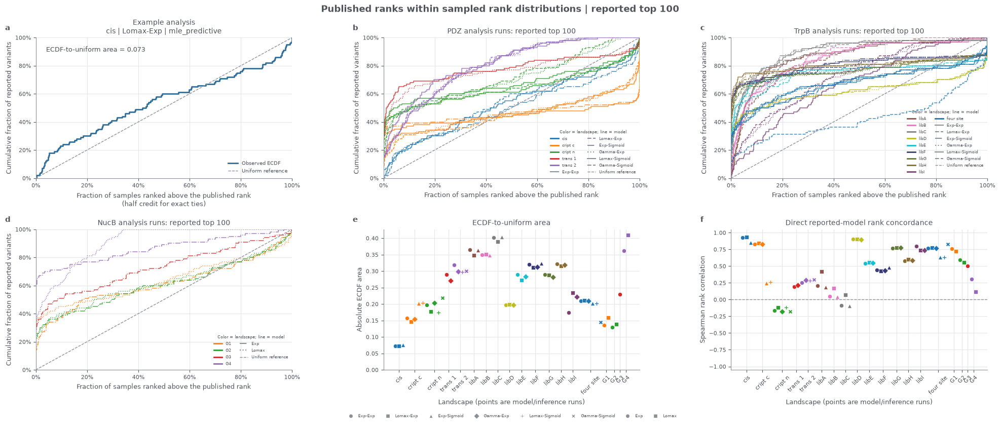

In [2]:
figure_1 = figure_reported_order(
    tables, cohort_top_n=MAIN_K, example_id=REPRESENTATIVE_IDS[0]
)
display(figure_1)
save_figure(figure_1, FIGURE_DIR, 'figure1_reported_order')
plt.close(figure_1)

## Figure 2: Rank uncertainty

Central 90% sampled-rank intervals summarize variation across repeated count experiments at fixed MLE parameters.

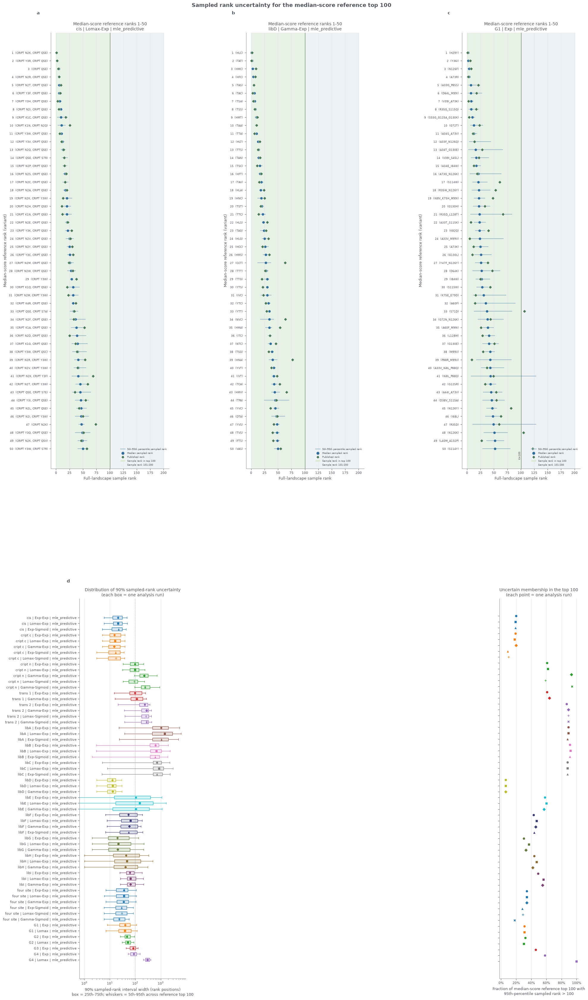

In [3]:
figure_2 = figure_rank_uncertainty(
    tables, representative_ids=REPRESENTATIVE_IDS, main_k=MAIN_K
)
display(figure_2)
save_figure(figure_2, FIGURE_DIR, 'figure2_rank_uncertainty')
plt.close(figure_2)

## Figure 3: Top-K decision stability

The detailed view uses $K=100$; curves also show $K=1,2,5,10,20,50,200,500,1000$.

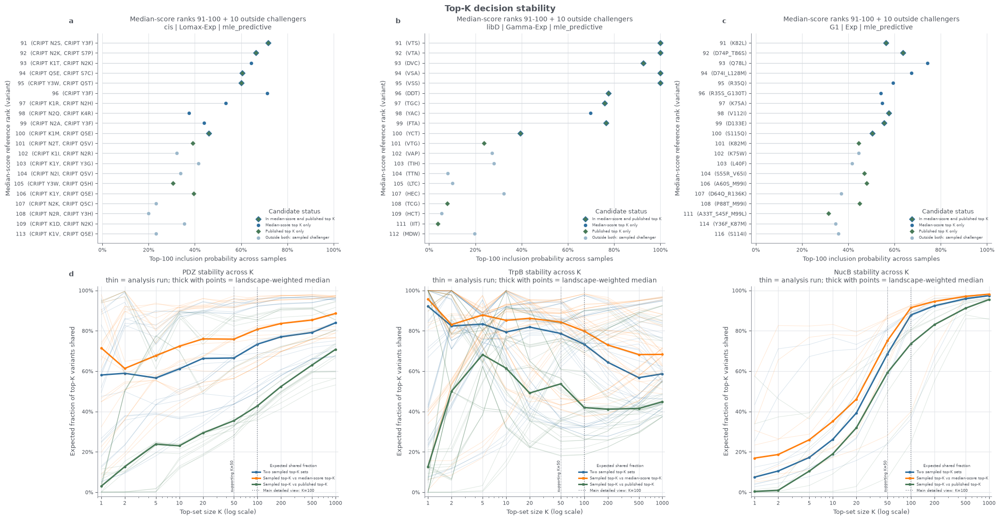

In [4]:
figure_3 = figure_top_k_stability(
    tables, representative_ids=REPRESENTATIVE_IDS, main_k=MAIN_K
)
display(figure_3)
save_figure(figure_3, FIGURE_DIR, 'figure3_top_k_stability')
plt.close(figure_3)

## Mechanism-table boundary

Figures 4--10 use aligned observed counts, all-candidate median proxy scores, and complete score/rank trajectories for the displayed cohorts. These associations are descriptive and model-conditional. They do not estimate the causal effect of sequencing depth.

## Figure 4: From experimental support to ranking resolution

Proxy-score spread is normalized by the run's top-1,000 median-score IQR and related to count support, local score crowding, and sampled-rank spread.

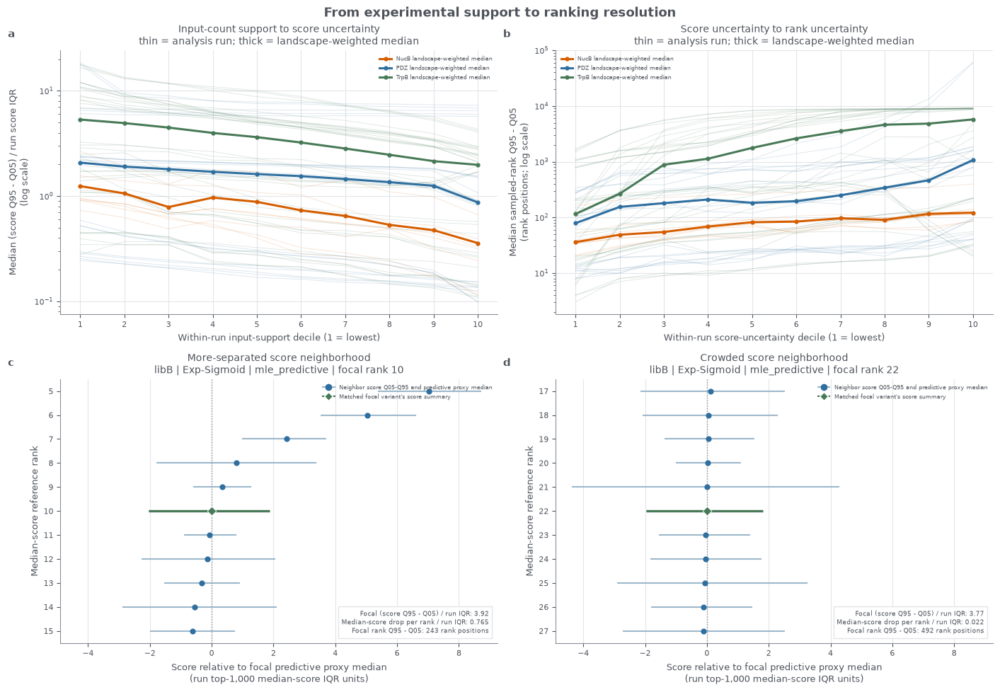

In [5]:
figure_4 = figure_ranking_mechanisms(mechanism_tables)
display(figure_4)
save_figure(figure_4, FIGURE_DIR, 'figure4_ranking_mechanisms')
plt.close(figure_4)

## Figure 5: Rank-space sensitivity view

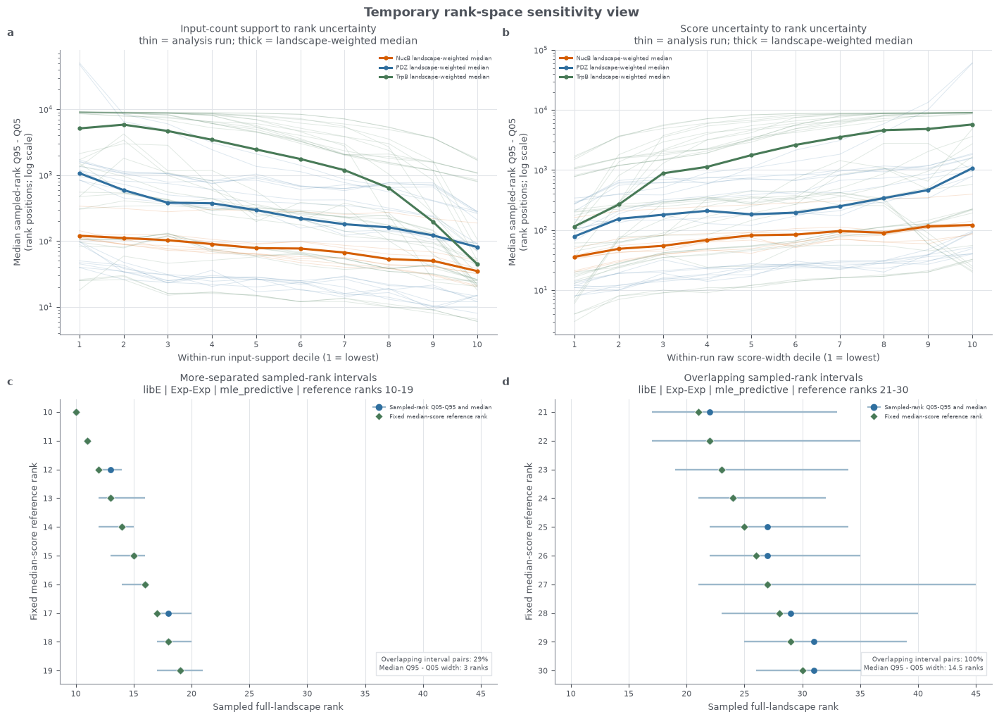

In [6]:
figure_5 = figure_rank_space_sensitivity(mechanism_tables)
display(figure_5)
save_figure(figure_5, FIGURE_DIR, 'figure5_rank_space_sensitivity')
plt.close(figure_5)

## Figure 6: Count-support renderer comparison

The scatter, datashader, and hexbin renderers display the same count-support and predictive proxy-uncertainty relationship.

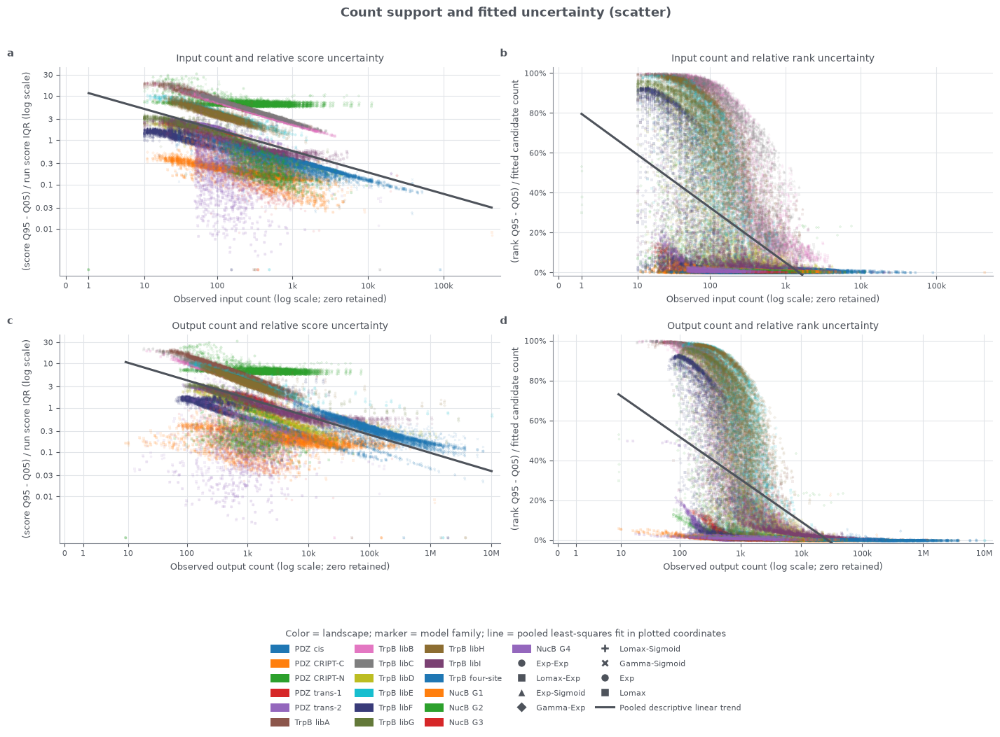

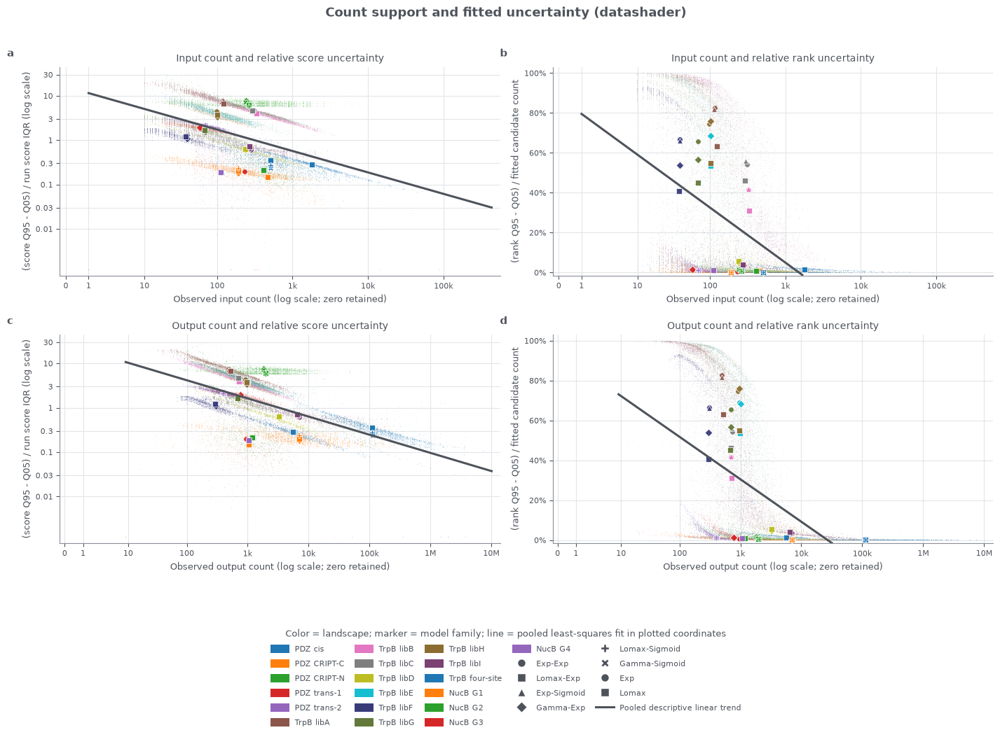

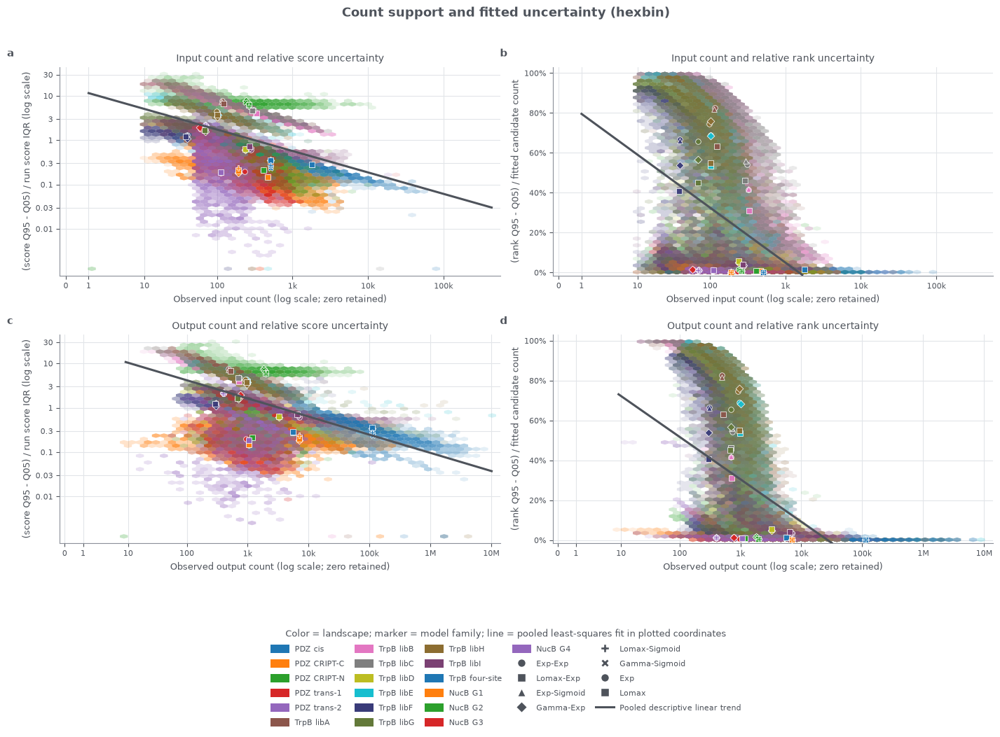

In [7]:
figure_6_1 = figure_count_uncertainty_scatter(mechanism_tables)
display(figure_6_1)
save_figure(figure_6_1, FIGURE_DIR, 'figure6_1_count_uncertainty_scatter')
plt.close(figure_6_1)

figure_6_2 = figure_count_uncertainty_datashader(mechanism_tables)
display(figure_6_2)
save_figure(figure_6_2, FIGURE_DIR, 'figure6_2_count_uncertainty_datashader')
plt.close(figure_6_2)

figure_6_3 = figure_count_uncertainty_hexbin(mechanism_tables)
display(figure_6_3)
save_figure(figure_6_3, FIGURE_DIR, 'figure6_3_count_uncertainty_hexbin')
plt.close(figure_6_3)

## Figure 7: Family-specific count support versus score and rank uncertainty

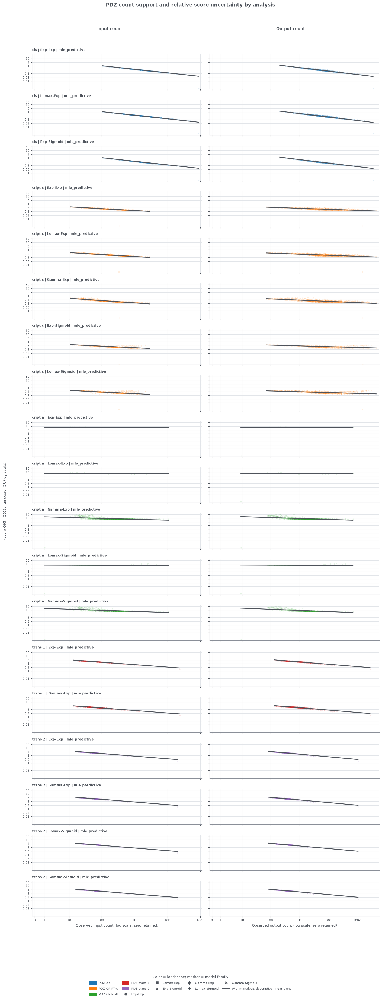

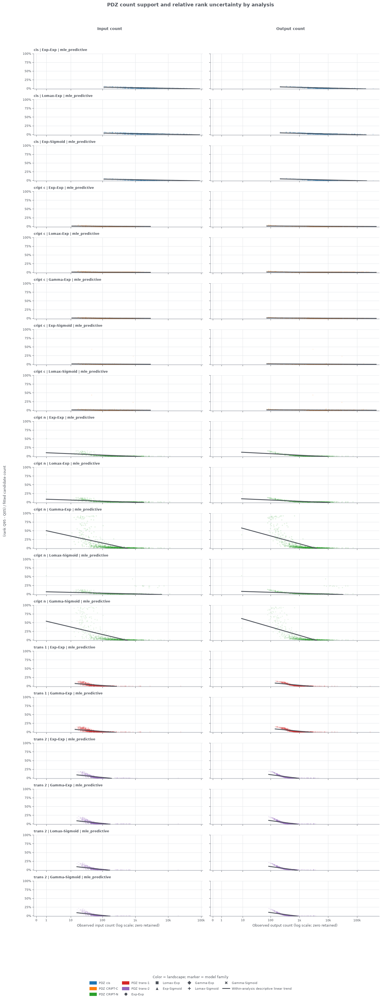

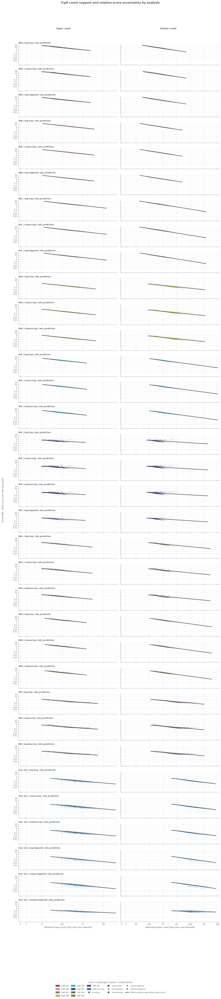

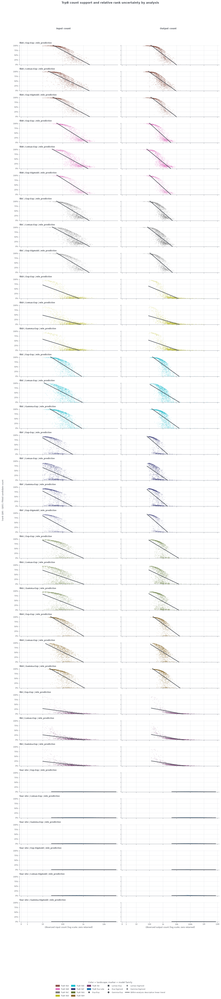

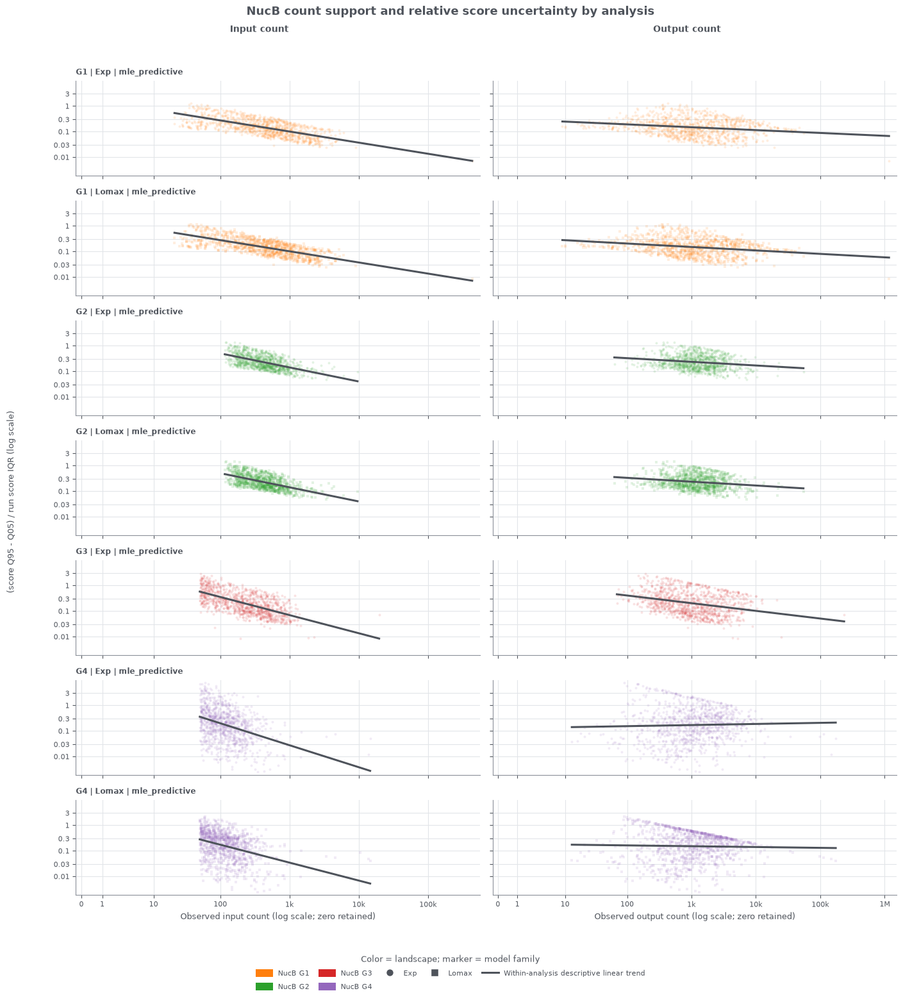

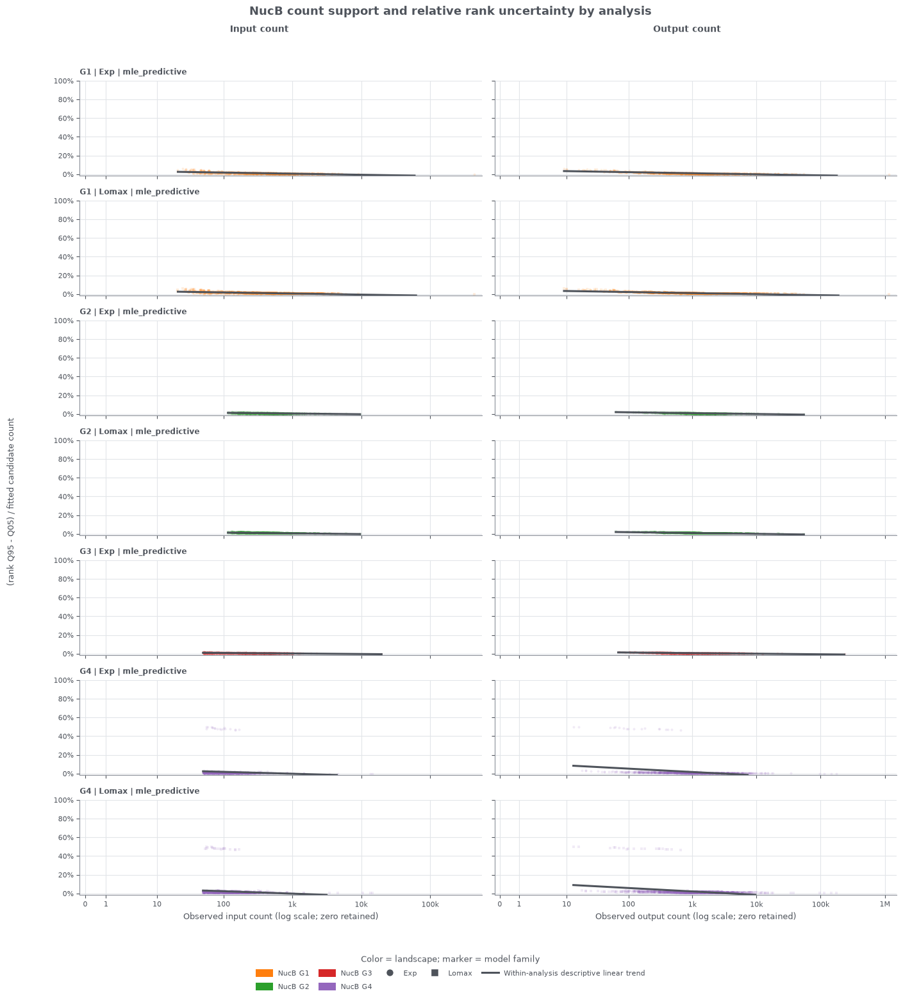

In [8]:
for family in ('pdz', 'trpb', 'nuc'):
    stem = FAMILY_FILE_STEMS[family]
    score_figure = figure_count_score_uncertainty_by_analysis(
        mechanism_tables, protein_family=family
    )
    display(score_figure)
    save_figure(
        score_figure, FIGURE_DIR, f'figure7_1_{stem}_count_score_uncertainty'
    )
    plt.close(score_figure)

    rank_figure = figure_count_rank_uncertainty_by_analysis(
        mechanism_tables, protein_family=family
    )
    display(rank_figure)
    save_figure(
        rank_figure, FIGURE_DIR, f'figure7_2_{stem}_count_rank_uncertainty'
    )
    plt.close(rank_figure)

## Figure 8: Median proxy-score landscape geometry

These panels show score distributions and rank-100 cutoffs. They are not binary functionality estimates. Axis labels identify the family-specific proxy contract.

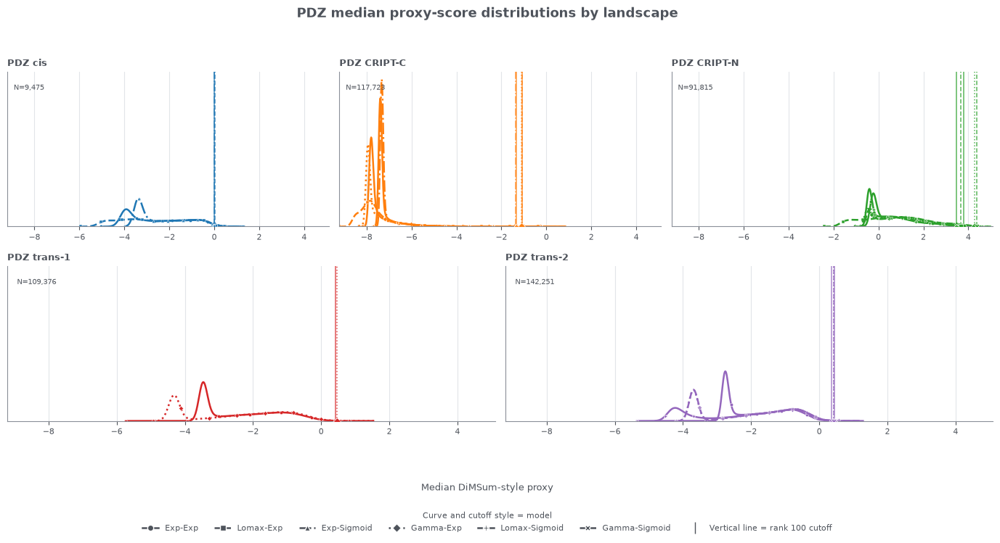

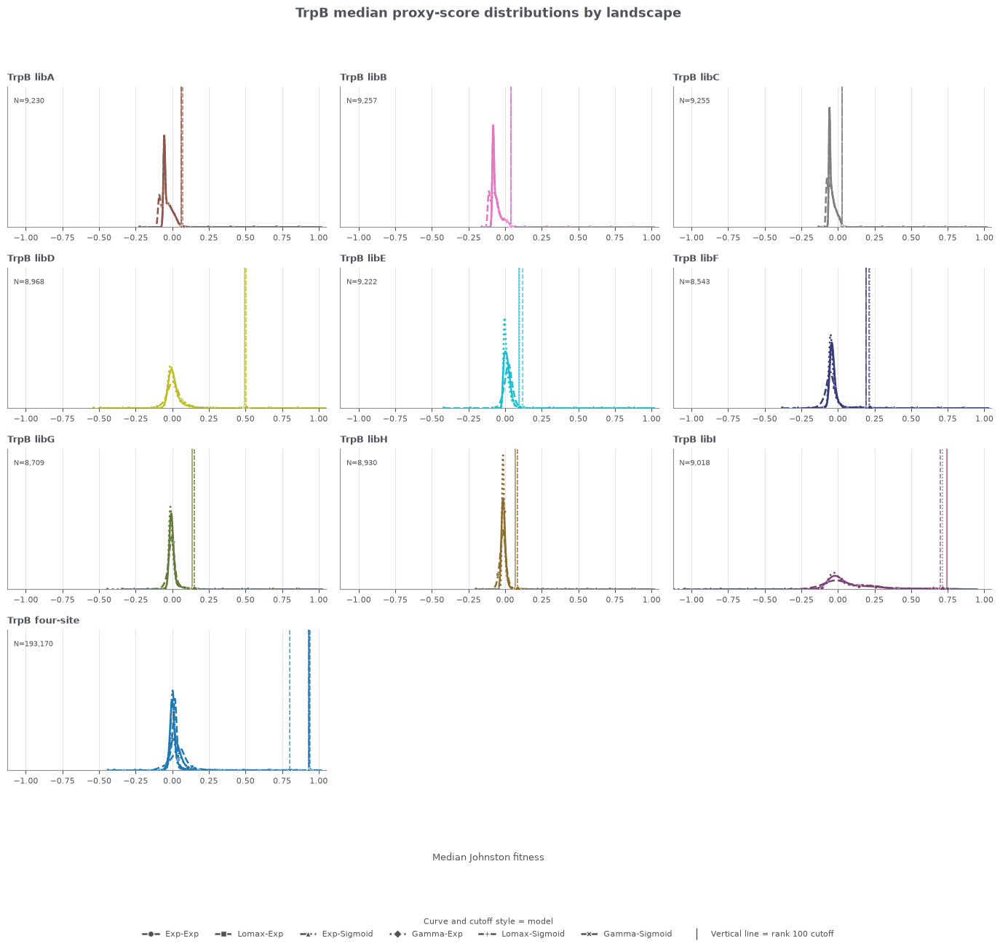

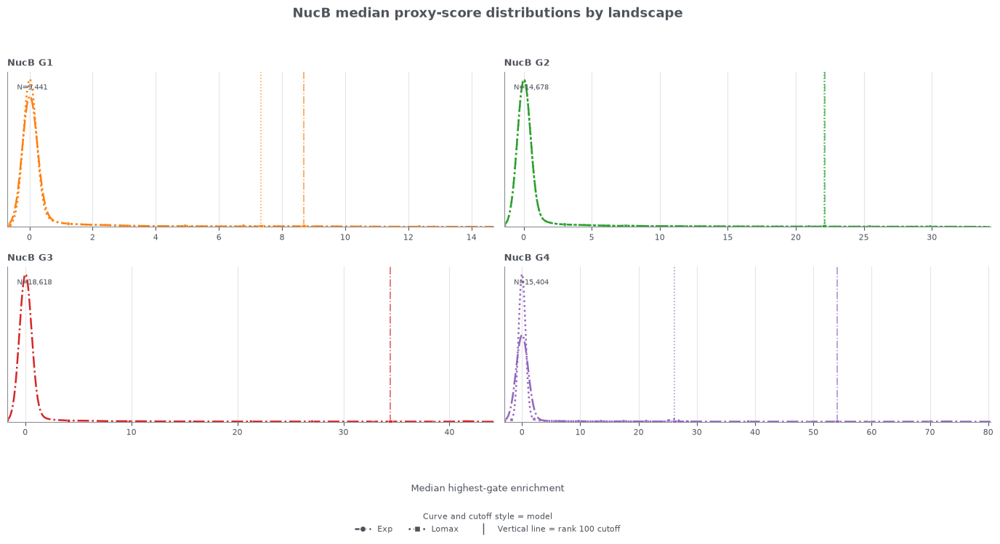

In [9]:
for family in ('pdz', 'trpb', 'nuc'):
    stem = FAMILY_FILE_STEMS[family]
    figure_8 = figure_functionality_distributions(
        inventory, functionality_scores, protein_family=family, top_k=MAIN_K
    )
    display(figure_8)
    save_figure(figure_8, FIGURE_DIR, f'figure8_{stem}_functionality')
    plt.close(figure_8)

## Figure 9: Decision-relative proxy score and uncertainty

The horizontal coordinate centers each median proxy score at the fixed rank-100 boundary. The vertical coordinate is the central 90% predictive proxy width, normalized by the top-1,000 score IQR.

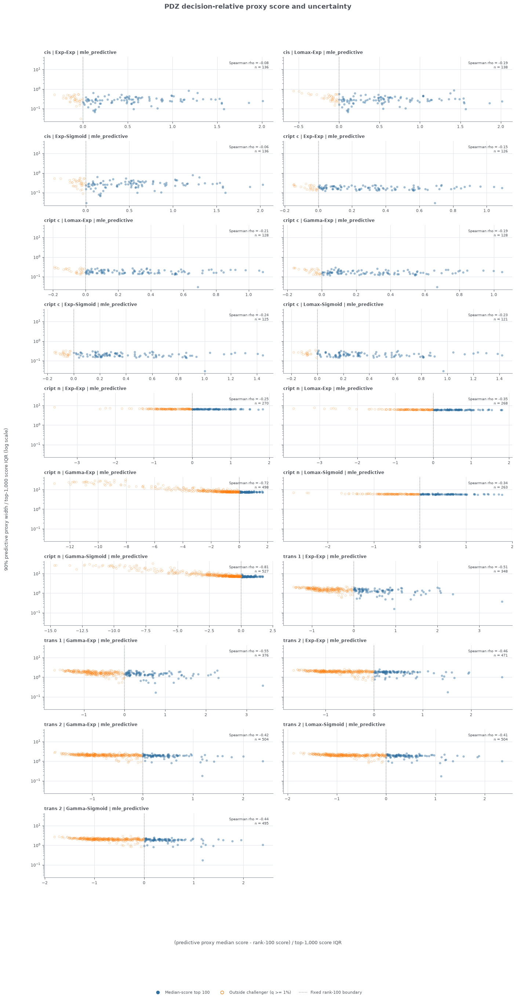

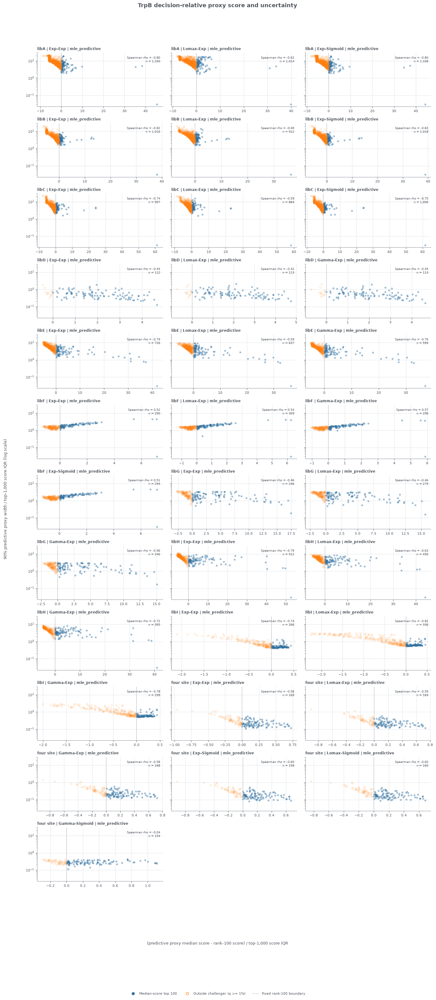

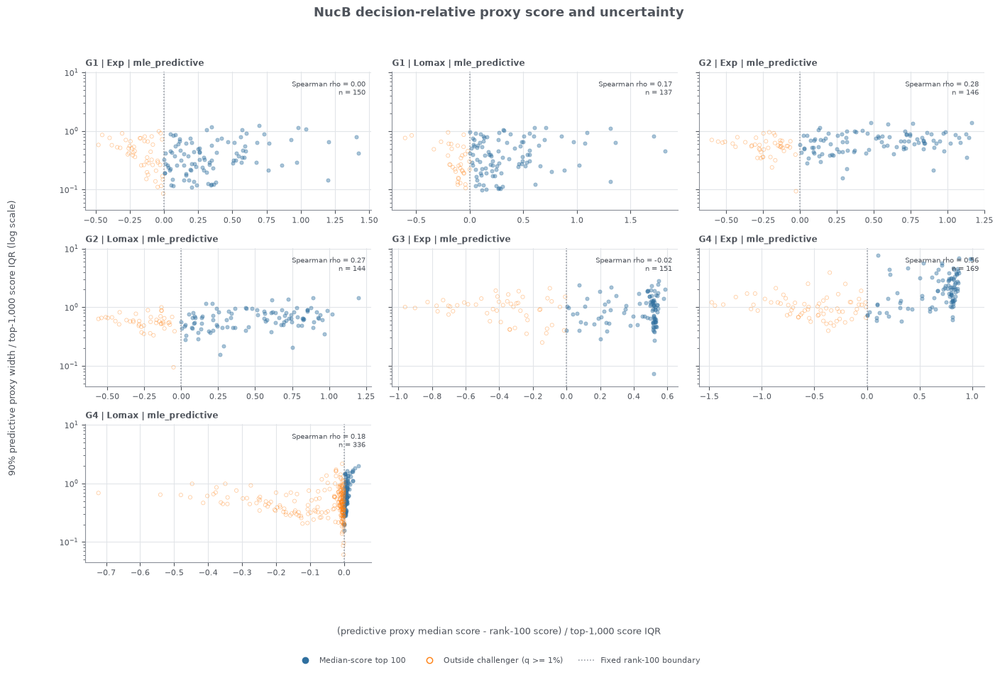

In [10]:
for family in ('pdz', 'trpb', 'nuc'):
    stem = FAMILY_FILE_STEMS[family]
    figure_9 = figure_fitness_uncertainty_by_analysis(
        mechanism_tables, protein_family=family
    )
    display(figure_9)
    save_figure(figure_9, FIGURE_DIR, f'figure9_{stem}_fitness_uncertainty')
    plt.close(figure_9)

## Figure 10: Per-analysis summary of top-100 instability

Each row relates input support, output abundance, and decision margin to predictive proxy spread and top-100 inclusion. The relationships are descriptive and non-causal.

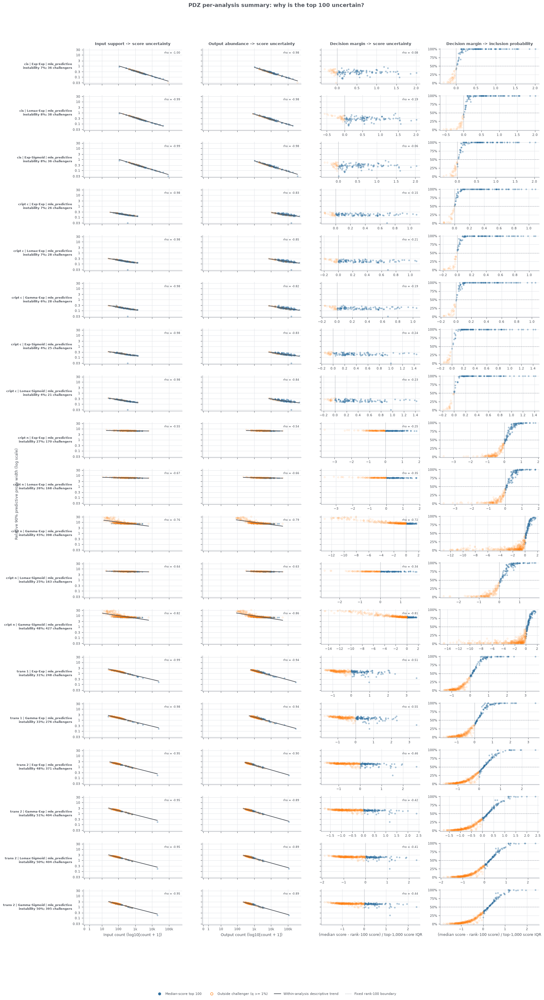

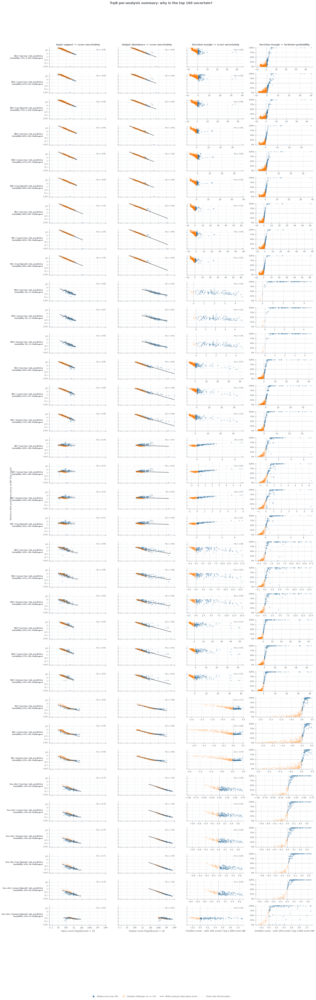

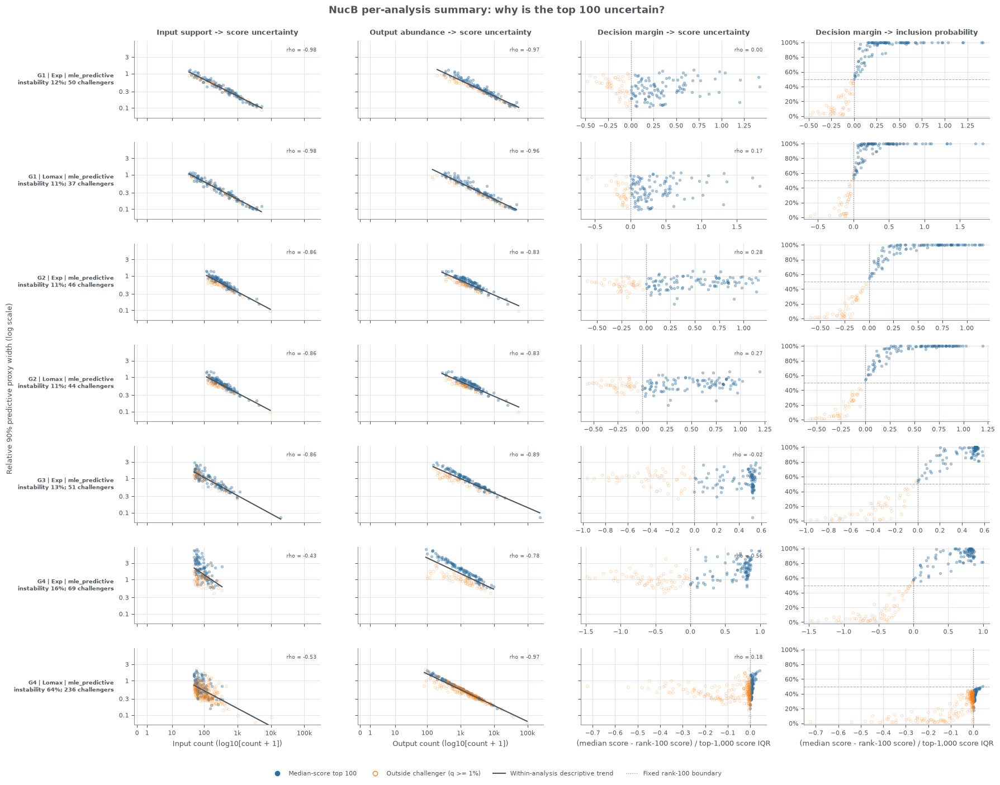

In [11]:
for family in ('pdz', 'trpb', 'nuc'):
    stem = FAMILY_FILE_STEMS[family]
    figure_10 = figure_summary_why_by_analysis(
        mechanism_tables, protein_family=family
    )
    display(figure_10)
    save_figure(figure_10, FIGURE_DIR, f'figure10_{stem}_summary_why')
    plt.close(figure_10)

## NucB reference and candidate audit

Source controls remain in abundance normalization and are excluded from ranking. The tables below cover G1--G4 score contracts and separate model-top, challenger, and reported reference summaries.

In [12]:
display(
    reference_diagnostics[reference_diagnostics['protein_family'].eq('nuc')][
        [
            'fit_id',
            'n_fitted_variants',
            'n_ranking_candidates',
            'n_excluded_from_ranking',
            'all_finite_spearman',
            'model_reported_top_k_intersection',
        ]
    ]
)
display(reference_category_sensitivity)
display(
    mechanism_diagnostics[mechanism_diagnostics['protein_family'].eq('nuc')]
)

,fit_id,n_fitted_variants,n_ranking_candidates,n_excluded_from_ranking,all_finite_spearman,model_reported_top_k_intersection
53,mle_55,10760,9441,1319,0.976944,83
54,mle_56,10760,9441,1319,0.979186,80
55,mle_57,14755,14678,77,0.678605,81
56,mle_58,14755,14678,77,0.679218,81
57,mle_59,18790,18618,172,0.635777,67
58,mle_61,15554,15404,150,0.732016,39
59,mle_62,15554,15404,150,0.744395,29


,analysis_id,protein_family,landscape,model_spec,cohort,top_k,category_column,category,count,fraction
0,nuc__nuc-g1__mle-predictive__exponential__mle-55,nuc,nuc-G1,exponential,model_top_k,100,reported_activity_level,activity_greater_than_WT,49,0.49
1,nuc__nuc-g1__mle-predictive__exponential__mle-55,nuc,nuc-G1,exponential,model_top_k,100,reported_activity_level,activity_greater_than_0,48,0.48
2,nuc__nuc-g1__mle-predictive__exponential__mle-55,nuc,nuc-G1,exponential,model_top_k,100,reported_activity_level,non-functional,3,0.03
3,nuc__nuc-g1__mle-predictive__exponential__mle-55,nuc,nuc-G1,exponential,reported_top_k,100,reported_activity_level,activity_greater_than_WT,51,0.51
4,nuc__nuc-g1__mle-predictive__exponential__mle-55,nuc,nuc-G1,exponential,reported_top_k,100,reported_activity_level,activity_greater_than_0,47,0.47
5,nuc__nuc-g1__mle-predictive__exponential__mle-55,nuc,nuc-G1,exponential,reported_top_k,100,reported_activity_level,non-functional,2,0.02
6,nuc__nuc-g1__mle-predictive__lomax__mle-56,nuc,nuc-G1,lomax,model_top_k,100,reported_activity_level,activity_greater_than_WT,50,0.50
7,nuc__nuc-g1__mle-predictive__lomax__mle-56,nuc,nuc-G1,lomax,model_top_k,100,reported_activity_level,activity_greater_than_0,44,0.44
8,nuc__nuc-g1__mle-predictive__lomax__mle-56,nuc,nuc-G1,lomax,model_top_k,100,reported_activity_level,non-functional,6,0.06
9,nuc__nuc-g1__mle-predictive__lomax__mle-56,nuc,nuc-G1,lomax,reported_top_k,100,reported_activity_level,activity_greater_than_WT,51,0.51


,analysis_id,protein_family,landscape,model_spec,stratum,n_variants,input_support_vs_score_uncertainty_spearman,output_abundance_vs_score_uncertainty_spearman,decision_margin_vs_score_uncertainty_spearman,decision_margin_vs_inclusion_probability_spearman,decision_margin_vs_score_uncertainty_partial_spearman_input_adjusted,source_control_rows
159,nuc__nuc-g1__mle-predictive__exponential__mle-55,nuc,nuc-G1,exponential,primary,150,-0.981290,-0.967144,0.001477,0.920127,0.191495,0
160,nuc__nuc-g1__mle-predictive__exponential__mle-55,nuc,nuc-G1,exponential,model_top_k,100,-0.979091,-0.979754,0.282076,0.758411,-0.014718,0
161,nuc__nuc-g1__mle-predictive__exponential__mle-55,nuc,nuc-G1,exponential,challengers,50,-0.989532,-0.986843,-0.452773,0.717874,0.143861,0
162,nuc__nuc-g1__mle-predictive__lomax__mle-56,nuc,nuc-G1,lomax,primary,137,-0.976662,-0.964302,0.167094,0.905749,0.196743,0
163,nuc__nuc-g1__mle-predictive__lomax__mle-56,nuc,nuc-G1,lomax,model_top_k,100,-0.975373,-0.973831,0.164080,0.762540,0.027020,0
164,nuc__nuc-g1__mle-predictive__lomax__mle-56,nuc,nuc-G1,lomax,challengers,37,-0.982573,-0.988916,-0.425794,0.783310,-0.251937,0
165,nuc__nuc-g2__mle-predictive__exponential__mle-57,nuc,nuc-G2,exponential,primary,146,-0.855271,-0.832010,0.277877,0.958933,0.768102,0
166,nuc__nuc-g2__mle-predictive__exponential__mle-57,nuc,nuc-G2,exponential,model_top_k,100,-0.938411,-0.928125,0.259034,0.882394,0.546049,0
167,nuc__nuc-g2__mle-predictive__exponential__mle-57,nuc,nuc-G2,exponential,challengers,46,-0.899319,-0.947209,-0.214431,0.865743,0.356456,0
168,nuc__nuc-g2__mle-predictive__lomax__mle-58,nuc,nuc-G2,lomax,primary,144,-0.855693,-0.834745,0.271714,0.954656,0.769575,0


## Figure 11: Joint count support and predictive proxy uncertainty

Each small corner is one analysis. Within each horizontal block, each column is one landscape and its fitted models are stacked vertically; blocks contain at most three landscapes so the corner panels remain readable. The plotted variant cohort is the median-score top 100, outside variants with at least 1% sampled top-100 inclusion probability, and eligible reported top-1,000 context. Diagonal panels show black KDEs in the displayed coordinates for observed input count, observed output count, and relative predictive proxy uncertainty. Lower-triangle panels show all three pairwise relationships: tiny gray points are reported-context-only variants, small filled blue circles are median-score top-100 variants, and small hollow orange circles are challengers. Upper-triangle cells report within-analysis Spearman correlations. Counts use $\log_{10}(n+1)$ so zeros are retained. Relative score uncertainty is the 90% predictive proxy width divided by the run score IQR and is displayed on a log scale. Axis limits are shared within each protein family. These conditional predictive distributions do not include parameter or MLE-estimator uncertainty.

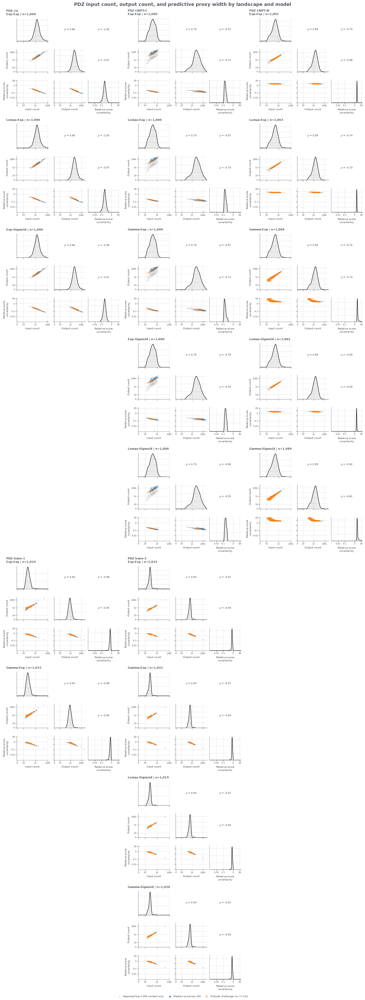

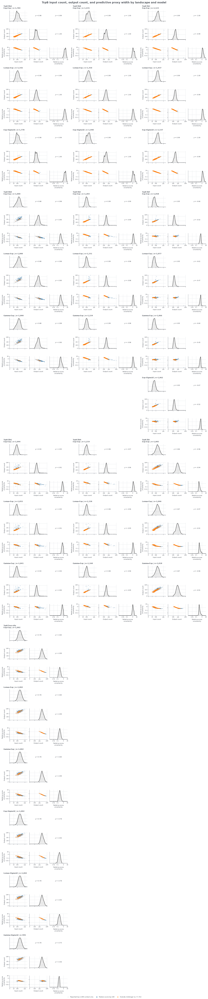

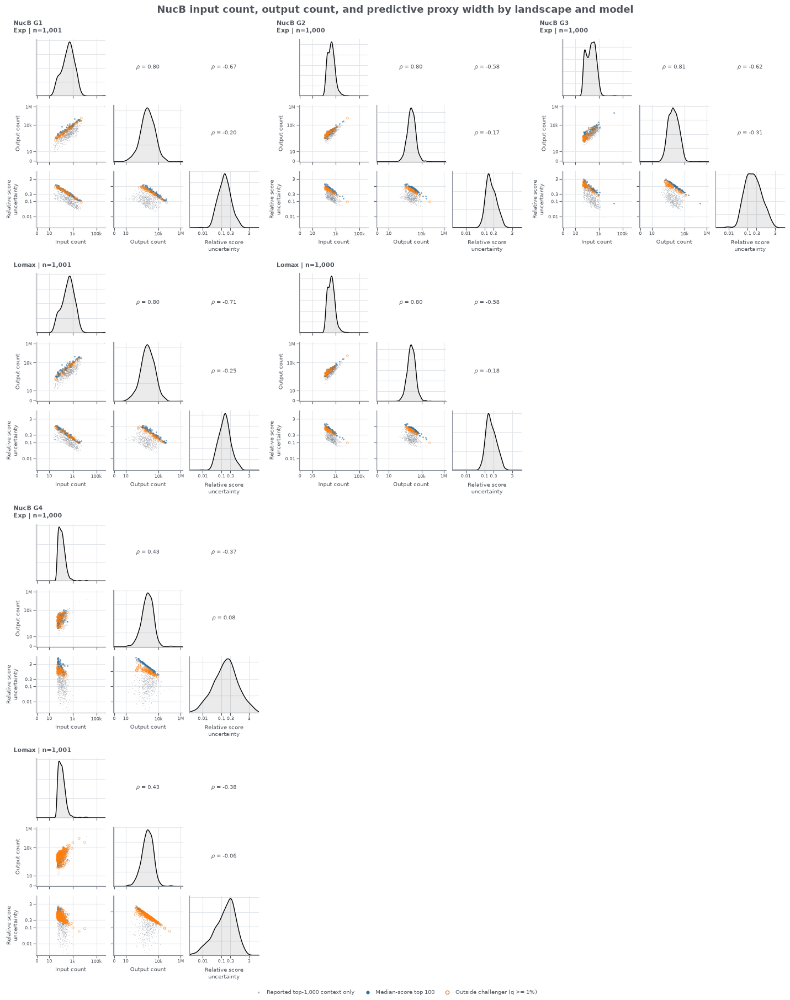

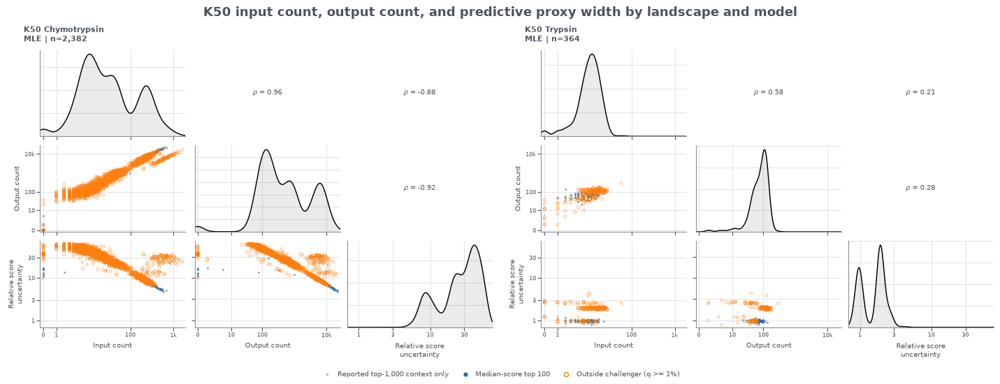

In [5]:
from figures import FAMILY_FILE_STEMS, figure_count_score_corner_by_analysis

figure_11_tables = load_mechanism_tables(TABLE_DIR)
figure_11_families = inventory["protein_family"].drop_duplicates().tolist()
for family in figure_11_families:
    figure_11 = figure_count_score_corner_by_analysis(
        figure_11_tables,
        protein_family=family,
    )
    display(figure_11)
    save_figure(
        figure_11,
        FIGURE_DIR,
        f"figure11_{FAMILY_FILE_STEMS[family]}_count_score_corner",
    )
    plt.close(figure_11)